<a href="https://colab.research.google.com/github/mezniyoussef206-hub/Data-201-Project1/blob/main/Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project 1 Data 201**





In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import make_pipeline


In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Reading the data
Bank = pd.read_csv("/content/drive/My Drive/Data 201/Datasets/bank-full.csv", sep=';')
Bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


#*Part 1: Understand Your Problem*

#1)

We have each row represents one customer  

My response Variable is Y

My response classes are Yes or No


#2)

 The predictors that might be:


Default-Balance-Contact-duration-campagain-pdays-previous-poutcome


In [ ]:
Bank.shape

(45211, 17)

#3)

In [ ]:
Bank["y"].value_counts()

,count
y,
no,39922
yes,5289


In [ ]:
#Print the count of the target Variable y with it's percentage
class_counts = Bank['y'].value_counts()
class_percentages = Bank['y'].value_counts(normalize=True) * 100

imbalance_df = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_percentages
})
#Creating a table to see it
print("--- Target Variable 'y' Distribution ---")
display(imbalance_df)

--- Target Variable 'y' Distribution ---


,Count,Percentage (%)
y,,
no,39922,88.30152
yes,5289,11.69848


Summary statistics by Class (y):
     campaign                        duration                      
         mean       std      skew        mean         std      skew
y                                                                  
no   2.846350  3.212767  4.801655  221.182806  207.383237  3.589357
yes  2.141047  1.921826  4.376876  537.294574  392.525262  1.704910


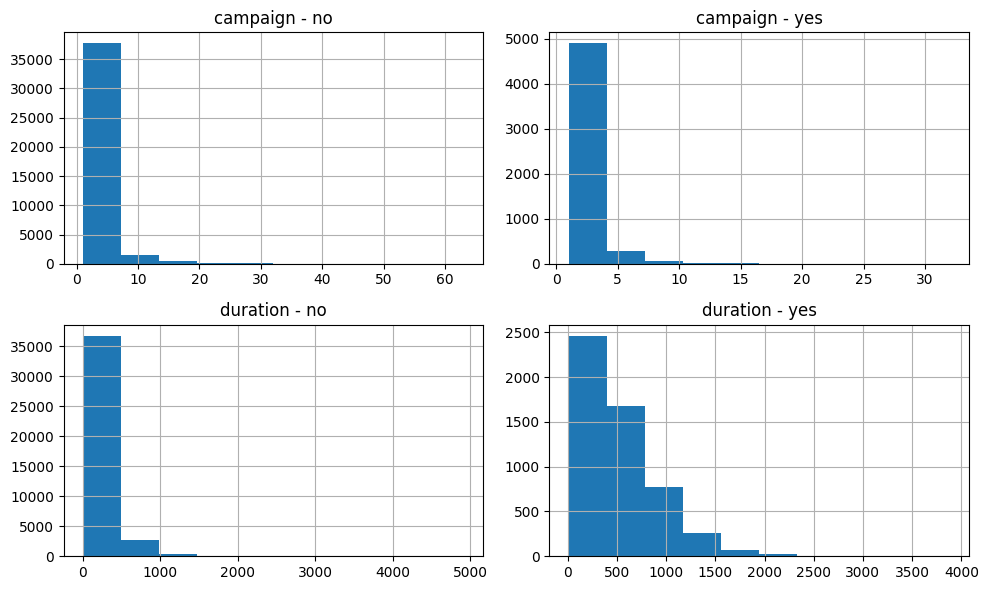

In [ ]:
#Cheking the if my variables campaign and duration are imbalanced
print("Summary statistics by Class (y):")
print(Bank.groupby("y")[["campaign", "duration"]].agg(["mean", "std", "skew"]))


fig, axes = plt.subplots(2, 2, figsize=(10, 6))

Bank[Bank["y"] == "no"]["campaign"].hist(ax=axes[0,0])
axes[0,0].set_title("campaign - no")

Bank[Bank["y"] == "yes"]["campaign"].hist(ax=axes[0,1])
axes[0,1].set_title("campaign - yes")

Bank[Bank["y"] == "no"]["duration"].hist(ax=axes[1,0])
axes[1,0].set_title("duration - no")

Bank[Bank["y"] == "yes"]["duration"].hist(ax=axes[1,1])
axes[1,1].set_title("duration - yes")

plt.tight_layout()
plt.show()

 Investigate your features and predictors.  

 My features are:
 loan
 duration
 campaign
 pdays
 previous
 poutcome

 Predictor: Y

In [ ]:
#My variable loan is binary So I need to encoded first
Bank["loan"].value_counts()

,count
loan,
no,37967
yes,7244


In [ ]:
#other is intereting here so I do have to encoded it
Bank['poutcome'].value_counts()

,count
poutcome,
unknown,36959
failure,4901
other,1840
success,1511


In [ ]:
#At first I thought that -1 means NA then when I checked the quotation I found out that it means ........
Bank['pdays'].value_counts()

,count
pdays,
-1,36954
182,167
92,147
183,126
91,126
...,...
749,1
769,1
587,1


In [ ]:
#Perivous is quantitve variable so it's totally fine
Bank[['previous']].value_counts()

,count
previous,
0,36954
1,2772
2,2106
3,1142
4,714
5,459
6,277
7,205
8,129


In [ ]:
#My campaign variable is totally fine as well
Bank[['campaign']].value_counts()

,count
campaign,
1,17544
2,12505
3,5521
4,3522
5,1764
6,1291
7,735
8,540
9,327


In [ ]:
Bank[['campaign', 'pdays', 'previous']].describe()

,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000
mean,2.763841,40.197828,0.580323
std,3.098021,100.128746,2.303441
min,1.000000,-1.000000,0.000000
25%,1.000000,-1.000000,0.000000
50%,2.000000,-1.000000,0.000000
75%,3.000000,-1.000000,0.000000
max,63.000000,871.000000,275.000000


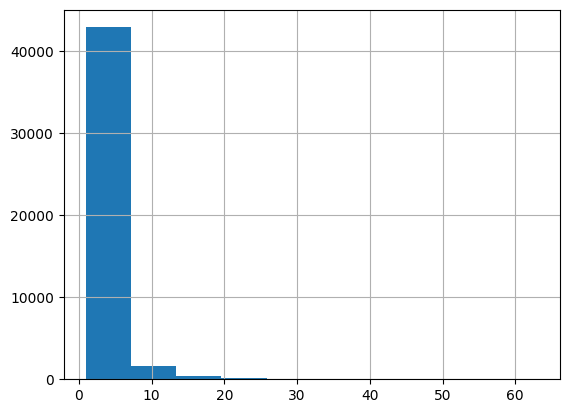

In [ ]:
Bank['campaign'].hist()
plt.show()

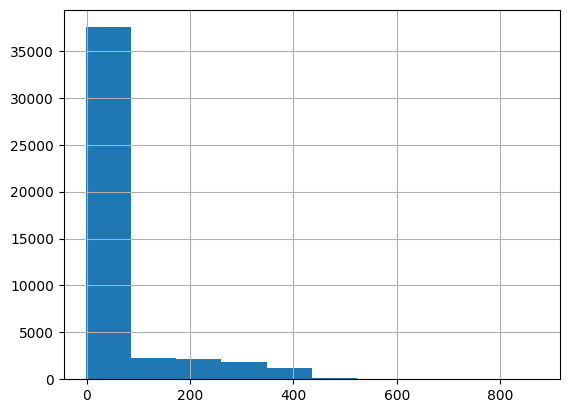

In [ ]:
Bank['pdays'].hist()
plt.show()

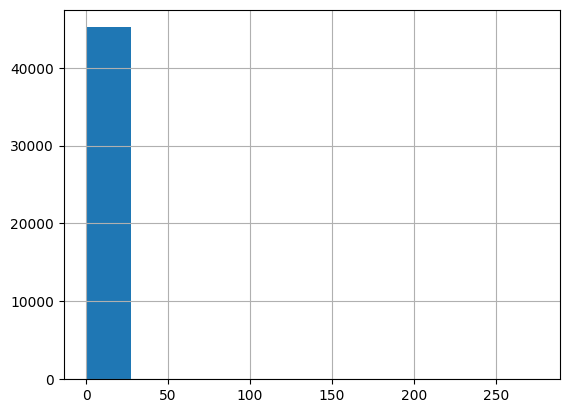

In [ ]:
Bank['previous'].hist()
plt.show()

In [ ]:
Bank.isna().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


#5)

I was thinking to add duration as a feature than I found out that it’s gonna be a data leakage because the duration of call can tell us about the decision For example a 10 secs calls means a directly No, Perhaps a long duration might be a Yes

In [ ]:
# set your features and target
X = Bank[["campaign", "poutcome", "pdays", "previous", "loan"]]
y= Bank["y"]

train=(y=="yes")

X_train = X[train]
X_test = X[train]

y_train = y[train]
y_test = y[train]

In [ ]:
X_train.shape, X_test.shape

((5289, 5), (5289, 5))

In [ ]:
#I used ONE-HOT-ENCODER FROM WEEK 7
from sklearn.compose import ColumnTransformer

# Splitting my dataset
X = Bank[["campaign", "poutcome", "pdays", "previous", "loan"]]
y = Bank["y"]

# Perform the train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=10,
    stratify=y
)

##HERE I HAD TO USE AI BECAUSE WHEN I APPLIED THE ONE HOT ENCODING IT ENCODED ALL THE VARIABLES
# Set up ColumnTransformer to encode only categorical columns and leave others untouched
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown="ignore", sparse_output=False), ['poutcome', 'loan'])
    ],
    remainder='passthrough' # This ensures campaign, pdays, and previous remain quantitative
)

# Fit and transform the training data
train_encoded_array = preprocessor.fit_transform(X_train)
train_encoded = pd.DataFrame(
    train_encoded_array,
    columns=preprocessor.get_feature_names_out()
)

# Transform the test data
test_encoded_array = preprocessor.transform(X_test)
test_encoded = pd.DataFrame(
    test_encoded_array,
    columns=preprocessor.get_feature_names_out()
)

# Let's inspect the columns to make sure they look right
print("Encoded feature columns:")
print(train_encoded.columns.tolist())

Encoded feature columns:
['cat__poutcome_failure', 'cat__poutcome_other', 'cat__poutcome_success', 'cat__poutcome_unknown', 'cat__loan_no', 'cat__loan_yes', 'remainder__campaign', 'remainder__pdays', 'remainder__previous']


In [ ]:
display(train_encoded)
display(test_encoded)

,cat__poutcome_failure,cat__poutcome_other,cat__poutcome_success,cat__poutcome_unknown,cat__loan_no,cat__loan_yes,remainder__campaign,remainder__pdays,remainder__previous
0,0.0,0.0,0.0,1.0,1.0,0.0,5.0,-1.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0,2.0,123.0,1.0
2,0.0,0.0,0.0,1.0,1.0,0.0,3.0,-1.0,0.0
3,0.0,1.0,0.0,0.0,1.0,0.0,1.0,237.0,17.0
4,0.0,0.0,0.0,1.0,1.0,0.0,3.0,-1.0,0.0
...,...,...,...,...,...,...,...,...,...
33903,0.0,0.0,0.0,1.0,1.0,0.0,4.0,-1.0,0.0
33904,0.0,0.0,0.0,1.0,1.0,0.0,1.0,-1.0,0.0
33905,0.0,0.0,0.0,1.0,1.0,0.0,1.0,-1.0,0.0
33906,0.0,0.0,0.0,1.0,1.0,0.0,1.0,-1.0,0.0


,cat__poutcome_failure,cat__poutcome_other,cat__poutcome_success,cat__poutcome_unknown,cat__loan_no,cat__loan_yes,remainder__campaign,remainder__pdays,remainder__previous
0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,90.0,1.0
1,0.0,0.0,0.0,1.0,1.0,0.0,26.0,-1.0,0.0
2,0.0,0.0,0.0,1.0,1.0,0.0,1.0,-1.0,0.0
3,0.0,0.0,0.0,1.0,1.0,0.0,2.0,-1.0,0.0
4,0.0,0.0,0.0,1.0,1.0,0.0,2.0,-1.0,0.0
...,...,...,...,...,...,...,...,...,...
11298,0.0,0.0,0.0,1.0,1.0,0.0,6.0,-1.0,0.0
11299,0.0,0.0,0.0,1.0,1.0,0.0,1.0,-1.0,0.0
11300,0.0,0.0,0.0,1.0,1.0,0.0,1.0,-1.0,0.0
11301,0.0,0.0,0.0,1.0,1.0,0.0,2.0,-1.0,0.0


KNN

In [ ]:
#Week 5
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

#fit the model
knn.fit(train_encoded, y_train)

#predict test data
knn_pred = knn.predict(test_encoded)

#evaluate
accuracy_score(y_test, knn_pred)

0.8920640537910289

In [ ]:
#Test these possible values
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

#create an empty list
cv_scores = []

#Run cross-validation
for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        train_encoded,
        y_train,
        cv=5
    )

    cv_scores.append(scores.mean())

print(cv_scores)

[np.float64(0.7529146633321695), np.float64(0.884127658895301), np.float64(0.8880203811619809), np.float64(0.8896129361398927), np.float64(0.8901732732763163), np.float64(0.8909400739859332), np.float64(0.89173636017267), np.float64(0.8916478646012974)]


K=15  has the highest accuracy so I just have to double check in the graph

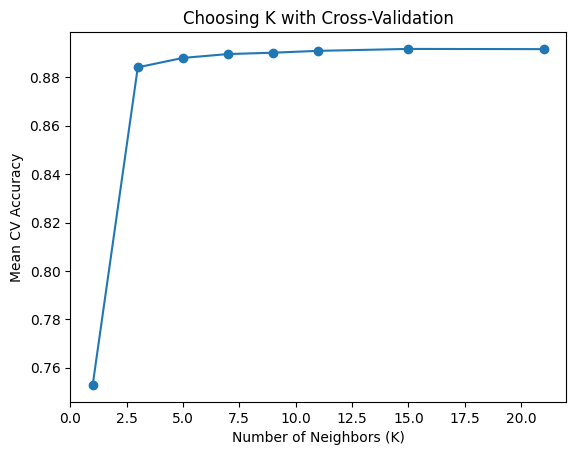

In [ ]:
plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("Choosing K with Cross-Validation")

plt.show()

From the graph we can see that Mean CV Accuracy kept raising up until we reached K = 15 then we started decreasing slightly

In [ ]:
best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

#fit
best_knn.fit(train_encoded, y_train)

#predict on test set
best_knn_pred = best_knn.predict(test_encoded)

#evaluate
accuracy_score(y_test, best_knn_pred)

0.8936565513580466

In [ ]:
# Threshold = 30%
prob_yes_knn = best_knn.predict_proba(test_encoded)[:, 1]

pred_30_knn = np.where(
    prob_yes_knn >= 0.30,
    "yes",
    "no"
)

# Confusion Matrix
cm_knn_30 = confusion_matrix(
    y_test,
    pred_30_knn,
    labels=["no", "yes"]
)

print(cm_knn_30)

TN_knn_30, FP_knn_30, FN_knn_30, TP_knn_30 = cm_knn_30.ravel()

print("TN:", TN_knn_30)
print("FP:", FP_knn_30)
print("FN:", FN_knn_30)
print("TP:", TP_knn_30)

[[9734  247]
 [1021  301]]
TN: 9734
FP: 247
FN: 1021
TP: 301


In [ ]:
# Accuracy
accuracy = accuracy_score(
    y_test,
    pred_30_knn
)

# Precision
precision = precision_score(
    y_test,
    pred_30_knn,
    pos_label="yes"
)

# Recall / Sensitivity
recall = recall_score(
    y_test,
    pred_30_knn,
    pos_label="yes"
)

# Specificity
specificity = TN / (TN + FP)

# F1 Score
f1 = f1_score(
    y_test,
    pred_30_knn,
    pos_label="yes"
)

# Convert target to 0 and 1 for ROC-AUC
y_test_binary = np.where(
    y_test == "yes",
    1,
    0
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)


Accuracy: 0.8878173936123153
Precision: 0.5492700729927007
Recall: 0.22768532526475038
Specificity: 0.9884781084059714
F1: 0.32192513368983955


I discovered that the models performed differently depending on which metric was considered. Logistic Regression and LDA had the highest accuracy and precision, while KNN had the highest recall and F1 score. In this application, a false negative means the model predicts that a customer will not subscribe when the customer actually would subscribe. I consider false negatives more costly because the bank could miss a potential customer, while a false positive mainly results in an unnecessary marketing call. For this reason, recall is especially important because it measures how many actual subscribers the model correctly identifies. F1 score is also useful because it balances recall and precision, so the model does not increase recall by making too many false positive predictions. Accuracy is less informative by itself because the dataset contains many more non-subscribers than subscribers. ROC-AUC is also useful because it shows how well the model separates subscribers from non-subscribers across different thresholds. Based on these considerations, KNN is useful for this application because it had the highest recall and F1 score among the four models.

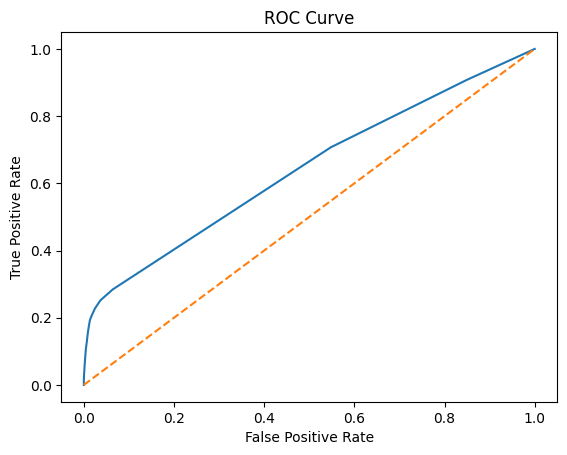

In [ ]:
#convert the response to 0/1
y_test_binary = np.where(
    y_test == "yes",
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes_knn
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()

In [ ]:
auc = roc_auc_score(
    y_test_binary,
    prob_yes_knn
)

print("AUC:", auc)

AUC: 0.6412080835584585


ROC-AUC tells us how well the model separates the “yes” and “no” classes across different thresholds. An AUC of 0.64 means the model performs better than random guessing, but there is still room for improvement.

The table and everything else is going to be in the slides